# Modélisation Texte — Expériences comparatives
## Rakuten France — Classification Multimodale

**Objectif :** Comparer différentes combinaisons d'input texte (désignation seule, description seule, combiné) avec et sans traduction, afin d'identifier le meilleur signal textuel pour la classification.

| Exp_ID | Input | Traduction | Statut |
|--------|-------|------------|--------|
| EXP_T01 | Désignation seule | Non | À faire |
| EXP_T02 | Description seule (fallback désig.) | Non | À faire |
| EXP_T03 | Désignation + Description | Non | À faire |
| EXP_T03b | Désig. + Desc. + Lemmatisation + Stopwords | Non | À faire |
| EXP_T04 | Désignation seule | → Français | À faire |
| EXP_T05 | Désignation + Description | → Français | À faire |
| EXP_T_KW | c-TF-IDF mots-clés par classe (Chi² selection) | Non | À faire |

**Modèle fixe :** TF-IDF (50k features, bigrammes) + LightGBM  
**Métrique principale :** Weighted F1-score

---
## 1. Imports et Configuration

In [24]:
import pandas as pd
import numpy as np
import pickle
import os
import warnings
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import lightgbm as lgb

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (14, 6)

BASE_PATH = r'C:\Users\xavie\Desktop\Rakuten'
PROCESSED_PATH = os.path.join(BASE_PATH, 'processed')

print('Imports OK')

Imports OK


---
## 2. Chargement des données

In [25]:
train = pd.read_csv(os.path.join(PROCESSED_PATH, 'train_processed.csv'), index_col=0)
test  = pd.read_csv(os.path.join(PROCESSED_PATH, 'test_processed.csv'),  index_col=0)

with open(os.path.join(PROCESSED_PATH, 'label_encoder.pkl'), 'rb') as f:
    le = pickle.load(f)

# Remplir les NaN (description manquante → chaîne vide)
for col in ['designation_clean', 'description_clean', 'text_combined']:
    train[col] = train[col].fillna('')
    test[col]  = test[col].fillna('')

print(f'Train : {train.shape}')
print(f'Test  : {test.shape}')
print(f'Classes : {train["label"].nunique()}')
train.head(3)

Train : (84916, 7)
Test  : (13812, 5)
Classes : 27


,designation_clean,description_clean,text_combined,productid,imageid,prdtypecode,label
0,olivia personalisiertes notizbuch 150 seiten p...,,olivia personalisiertes notizbuch 150 seiten p...,3804725264,1263597046,10,0
1,journal des arts le n 133 du 28 09 2001 l art ...,,journal des arts le n 133 du 28 09 2001 l art ...,436067568,1008141237,2280,18
2,grand stylet ergonomique bleu gamepad nintendo...,pilot style touch pen de marque speedlink est ...,grand stylet ergonomique bleu gamepad nintendo...,201115110,938777978,50,2


In [26]:
# Split 80/20 stratifié — identique au pipeline du coéquipier pour comparaison directe
X_tr, X_val, y_tr, y_val = train_test_split(
    train, train['label'],
    test_size=0.20,
    random_state=42,
    stratify=train['label']
)

print(f'Train     : {len(X_tr)} lignes')
print(f'Validation: {len(X_val)} lignes')

# Poids de classes — calculés sur le train uniquement
classes = np.unique(y_tr)
class_weights = compute_class_weight('balanced', classes=classes, y=y_tr)
weight_map = dict(zip(classes, class_weights))
sample_weights_tr = y_tr.map(weight_map).values

print(f'\nPoids min : {class_weights.min():.3f}, max : {class_weights.max():.3f}')

Train     : 67932 lignes
Validation: 16984 lignes

Poids min : 0.308, max : 4.118


---
## 3. Pipeline réutilisable

On définit une fonction unique `run_experiment()` pour garantir que toutes les expériences sont évaluées dans les mêmes conditions (mêmes splits, mêmes hyperparamètres LightGBM, même métrique).

In [27]:
# Dictionnaire global pour stocker tous les résultats
RESULTS = {}

def run_experiment(exp_id, text_train, text_val, y_train, y_val,
                   sample_weights, label_encoder,
                   tfidf_params=None, lgbm_params=None, verbose=True):
    """
    Lance un experiment complet : TF-IDF → LightGBM → évaluation.
    
    Paramètres
    ----------
    exp_id       : identifiant de l'expérience (ex: 'EXP_T01')
    text_train   : Series ou liste de textes pour l'entraînement
    text_val     : Series ou liste de textes pour la validation
    """
    t0 = time.time()
    
    # --- TF-IDF ---
    _tfidf_params = dict(
        max_features=50_000,
        ngram_range=(1, 2),
        sublinear_tf=True,
        min_df=2,
        strip_accents='unicode',
        analyzer='word'
    )
    if tfidf_params:
        _tfidf_params.update(tfidf_params)
    
    tfidf = TfidfVectorizer(**_tfidf_params)
    X_tfidf_tr  = tfidf.fit_transform(text_train)
    X_tfidf_val = tfidf.transform(text_val)
    
    # --- LightGBM ---
    _lgbm_params = dict(
        objective='multiclass',
        num_class=27,
        n_estimators=1000,
        learning_rate=0.05,
        num_leaves=127,
        n_jobs=-1,
        random_state=42,
        verbose=-1
    )
    if lgbm_params:
        _lgbm_params.update(lgbm_params)
    
    lgb_train = lgb.Dataset(X_tfidf_tr,  label=y_train, weight=sample_weights)
    lgb_val   = lgb.Dataset(X_tfidf_val, label=y_val,   reference=lgb_train)
    
    callbacks = [
        lgb.early_stopping(stopping_rounds=50, verbose=False),
        lgb.log_evaluation(period=100 if verbose else 0)
    ]
    
    params = {k: v for k, v in _lgbm_params.items()
              if k not in ('n_estimators', 'random_state', 'n_jobs', 'verbose')}
    params['seed'] = 42
    params['num_threads'] = -1
    
    model = lgb.train(
        params,
        lgb_train,
        num_boost_round=_lgbm_params['n_estimators'],
        valid_sets=[lgb_val],
        callbacks=callbacks
    )
    
    # --- Évaluation ---
    y_pred = model.predict(X_tfidf_val).argmax(axis=1)
    wf1  = f1_score(y_val, y_pred, average='weighted')
    mf1  = f1_score(y_val, y_pred, average='macro')
    acc  = (y_val == y_pred).mean()
    duration = time.time() - t0
    
    RESULTS[exp_id] = {
        'weighted_f1': wf1,
        'macro_f1':    mf1,
        'accuracy':    acc,
        'best_iter':   model.best_iteration,
        'duration_s':  duration,
        'model':       model,
        'tfidf':       tfidf,
        'y_pred':      y_pred
    }
    
    print(f'\n{'='*55}')
    print(f'  {exp_id}')
    print(f'{'='*55}')
    print(f'  Weighted F1 : {wf1:.4f}')
    print(f'  Macro F1    : {mf1:.4f}')
    print(f'  Accuracy    : {acc:.4f}')
    print(f'  Best iter   : {model.best_iteration}')
    print(f'  Durée       : {duration:.0f}s')
    
    return RESULTS[exp_id]

print('Pipeline défini.')

Pipeline défini.


---
## EXP_T01 — Désignation seule (sans traduction)

**Hypothèse :** La désignation seule, courte et dense en termes clés, suffit-elle à classifier correctement ?

In [15]:
res_t01 = run_experiment(
    exp_id     = 'EXP_T01',
    text_train = X_tr['designation_clean'],
    text_val   = X_val['designation_clean'],
    y_train    = y_tr,
    y_val      = y_val,
    sample_weights = sample_weights_tr,
    label_encoder  = le
)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.542605 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 192312
[LightGBM] [Info] Number of data points in the train set: 67932, number of used features: 6926
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[Ligh

---
## EXP_T02 — Description seule (fallback désignation si absente)

**Hypothèse :** La description contient-elle plus de signal que la désignation ?  
**Note :** 35% des produits n'ont pas de description → fallback sur la désignation pour ces produits.

In [ ]:
# Fallback : si description vide → utiliser la désignation
def desc_with_fallback(df):
    return df.apply(
        lambda row: row['description_clean'] if row['description_clean'].strip() != ''
                    else row['designation_clean'],
        axis=1
    )

text_t02_tr  = desc_with_fallback(X_tr)
text_t02_val = desc_with_fallback(X_val)

# Statistiques : combien de fallbacks ?
n_fallback_tr  = (X_tr['description_clean'].str.strip() == '').sum()
n_fallback_val = (X_val['description_clean'].str.strip() == '').sum()
print(f'Produits sans description (train) : {n_fallback_tr} ({n_fallback_tr/len(X_tr):.1%}) → fallback désignation')
print(f'Produits sans description (val)   : {n_fallback_val} ({n_fallback_val/len(X_val):.1%}) → fallback désignation')

res_t02 = run_experiment(
    exp_id     = 'EXP_T02',
    text_train = text_t02_tr,
    text_val   = text_t02_val,
    y_train    = y_tr,
    y_val      = y_val,
    sample_weights = sample_weights_tr,
    label_encoder  = le
)

Produits sans description (train) : 23984 (35.3%) → fallback désignation
Produits sans description (val)   : 5955 (35.1%) → fallback désignation
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 7.299465 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1274641
[LightGBM] [Info] Number of data points in the train set: 67932, number of used features: 41538
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] St

---
## EXP_T03 — Désignation + Description combinées (sans traduction)

**Hypothèse :** La concaténation des deux champs maximise le signal textuel disponible.

In [16]:
res_t03 = run_experiment(
    exp_id     = 'EXP_T03',
    text_train = X_tr['text_combined'],
    text_val   = X_val['text_combined'],
    y_train    = y_tr,
    y_val      = y_val,
    sample_weights = sample_weights_tr,
    label_encoder  = le
)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 8.722508 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1414249
[LightGBM] [Info] Number of data points in the train set: 67932, number of used features: 43253
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[Li

---
## EXP_T03b — Désig. + Desc. + Stemming + Stopwords

**Hypothèse :** Appliquer le stemming (SnowballStemmer français) et supprimer les stopwords réduit le bruit lexical et concentre le TF-IDF sur les racines porteuses de sens.

**Changements par rapport à EXP_T03 :**
- Stemming via NLTK `SnowballStemmer('french')` (vélos → vélo, piscines → piscin)
- Suppression des stopwords multilingues (NLTK : fr + en + de + es)

> **Note :** spaCy `fr_core_news_sm` incompatible avec Pydantic 2.x → remplacement par SnowballStemmer (plus rapide, ~30s vs ~15 min, résultat comparable pour TF-IDF)

In [17]:
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords
import nltk
nltk.download('stopwords', quiet=True)

stemmer = SnowballStemmer('french')

STOPWORDS = set(
    stopwords.words('french') +
    stopwords.words('english') +
    stopwords.words('german') +
    stopwords.words('spanish')
)

CACHE_LEMMA_PATH = os.path.join(PROCESSED_PATH, 'text_combined_stemmed.csv')

def stem_and_filter(texts):
    results = []
    for i, text in enumerate(texts):
        if not isinstance(text, str):
            results.append('')
            continue
        tokens = text.lower().split()
        stemmed = [
            stemmer.stem(tok)
            for tok in tokens
            if tok not in STOPWORDS and len(tok) > 2
        ]
        results.append(' '.join(stemmed))
        if (i + 1) % 10_000 == 0:
            print(f'  {i+1}/{len(texts)} textes traités...')
    return results

if os.path.exists(CACHE_LEMMA_PATH):
    print(f'Cache trouvé : {CACHE_LEMMA_PATH} — chargement...')
    cache_lemma = pd.read_csv(CACHE_LEMMA_PATH, index_col=0)
    train['text_lemmatized'] = cache_lemma['text_lemmatized']
    print('Cache chargé.')
else:
    print(f'Stemming de {len(train)} textes...')
    t0 = time.time()
    train['text_lemmatized'] = stem_and_filter(train['text_combined'].tolist())
    print(f'Terminé en {time.time()-t0:.0f}s')
    train[['text_lemmatized']].to_csv(CACHE_LEMMA_PATH)
    print(f'Cache sauvegardé : {CACHE_LEMMA_PATH}')

print('\nExemples avant/après stemming :')
for i in [0, 1, 2]:
    print(f'  AVANT : {train["text_combined"].iloc[i][:100]}')
    print(f'  APRÈS : {train["text_lemmatized"].iloc[i][:100]}')
    print()

Cache trouvé : C:\Users\xavie\Desktop\Rakuten\processed\text_combined_stemmed.csv — chargement...
Cache chargé.

Exemples avant/après stemming :
  AVANT : olivia personalisiertes notizbuch 150 seiten punktraster ca din a5 rosen design
  APRÈS : olivi personalisiert notizbuch 150 seiten punktrast din rosen design

  AVANT : journal des arts le n 133 du 28 09 2001 l art et son marche salon d art asiatique a paris jacques ba
  APRÈS : journal art 133 2001 art march salon art asiat paris jacqu barrer francois perri reform vent encher 

  AVANT : grand stylet ergonomique bleu gamepad nintendo wii u speedlink pilot style pilot style touch pen de 
  APRÈS : grand stylet ergonom bleu gamepad nintendo wii speedlink pilot styl pilot styl touch pen marqu speed



In [19]:
X_tr_lemma  = train.loc[X_tr.index]
X_val_lemma = train.loc[X_val.index]

# fillna : les lignes vides sont lues comme NaN depuis le CSV cache
text_tr_lemma  = X_tr_lemma['text_lemmatized'].fillna('')
text_val_lemma = X_val_lemma['text_lemmatized'].fillna('')

res_t03b = run_experiment(
    exp_id     = 'EXP_T03b',
    text_train = text_tr_lemma,
    text_val   = text_val_lemma,
    y_train    = y_tr,
    y_val      = y_val,
    sample_weights = sample_weights_tr,
    label_encoder  = le
)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 4.591273 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 912724
[LightGBM] [Info] Number of data points in the train set: 67932, number of used features: 28612
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[LightGBM] [Info] Start training from score -3.295837
[Lig

---
## EXP_T_KW — Mots-clés par classe via c-TF-IDF + Chi² selection

### Idée

Au lieu de traiter chaque document indépendamment, on calcule le **c-TF-IDF** (Class TF-IDF) : pour chaque classe, on concatène tous ses produits en un "super-document", puis on applique TF-IDF. Cela donne les termes les **plus représentatifs et discriminants de chaque classe**.

Formule c-TF-IDF :

$$\text{c-TF-IDF}(t, c) = \frac{f(t,c)}{|c|} \times \log\left(1 + \frac{A}{f(t)}\right)$$

Où $|c|$ = nombre de mots dans la classe, $A$ = moyenne des mots par classe, $f(t)$ = fréquence totale du terme.

### Comment l'utiliser comme features ?

On combine **deux sources de signal** :
1. **TF-IDF classique** (50k features) — signal lexical brut
2. **27 features de similarité cosinus** — proximité de chaque document avec le "centroïde c-TF-IDF" de chaque classe

La concaténation des deux donne un vecteur hybride : le modèle sait à la fois *quels mots* sont présents ET *à quelle classe* le texte ressemble le plus.

### Aller encore plus loin — variantes explorables
- **Sélection Chi²** : parmi les 50k features TF-IDF, ne garder que les K plus discriminantes par classe (plus interprétable, moins de bruit)
- **Augmentation des classes rares** : surpondérer les top mots des petites classes dans le TF-IDF
- **Visualisation WordCloud** par classe : exploitable directement dans le rapport

In [28]:
import scipy.sparse as sp
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import normalize

# ── Étape 1 : TF-IDF classique (même config qu'EXP_T03) ──────────────────────
tfidf_kw = TfidfVectorizer(
    max_features=50_000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=2,
    strip_accents='unicode'
)
X_tfidf_tr_kw  = tfidf_kw.fit_transform(X_tr['text_combined'])
X_tfidf_val_kw = tfidf_kw.transform(X_val['text_combined'])

vocab = tfidf_kw.get_feature_names_out()
print(f'Vocabulaire TF-IDF : {len(vocab)} termes')

# ── Étape 2 : c-TF-IDF — centroïdes de classe ────────────────────────────────
n_classes = 27
n_terms   = X_tfidf_tr_kw.shape[1]

# Pour chaque classe, sommer les vecteurs TF-IDF de tous ses documents → centroïde
class_centroids = np.zeros((n_classes, n_terms))
class_sizes     = np.zeros(n_classes)

for c in range(n_classes):
    mask = (y_tr.values == c)
    if mask.sum() > 0:
        class_centroids[c] = X_tfidf_tr_kw[mask].sum(axis=0)
        class_sizes[c]     = mask.sum()

# Normalisation c-TF-IDF : diviser par taille de la classe, pondérer par rareté inter-classes
term_freq_total = class_centroids.sum(axis=0)          # fréquence totale de chaque terme
avg_class_size  = class_sizes.mean()

# log(1 + A / f(t)) — amplifier les termes rares inter-classes
idf_class = np.log1p(avg_class_size / (term_freq_total + 1e-10))
ctfidf_matrix = (class_centroids / (class_sizes[:, None] + 1e-10)) * idf_class[None, :]

# Normaliser chaque centroïde (norme L2) pour la similarité cosinus
ctfidf_norm = ctfidf_matrix / (np.linalg.norm(ctfidf_matrix, axis=1, keepdims=True) + 1e-10)

print(f'Centroïdes c-TF-IDF : {ctfidf_norm.shape}  (27 classes × {n_terms} termes)')

# Top 15 mots par classe
CLASS_NAMES = {
    0: 'Livres', 1: 'Jeux vidéo PC', 2: 'Access. gaming', 3: 'Consoles',
    4: 'Dérivés geek', 5: 'Cartes collec.', 6: 'Figurines JS', 7: 'Jouets',
    8: 'Jeux société', 9: 'Petites voitures', 10: 'Access. enfance',
    11: 'Jeux extérieur', 12: 'Sacs/access.', 13: 'Mobilier', 14: 'Linge maison',
    15: 'Nourriture', 16: 'Lampes/déco', 17: 'Access. animaux', 18: 'Magazines',
    19: 'Livres & BDs', 20: 'Consoles/jeux', 21: 'Papeterie', 22: 'Mobilier ext.',
    23: 'Piscines/Spas', 24: 'Outillage', 25: 'BDs & livres', 26: 'Jeux DL'
}

print('\n── Top 10 mots discriminants par classe (c-TF-IDF) ──')
for c in range(n_classes):
    top_idx  = ctfidf_norm[c].argsort()[::-1][:10]
    top_words = [vocab[i] for i in top_idx]
    print(f'  {CLASS_NAMES.get(c, c):20s} → {", ".join(top_words)}')

Vocabulaire TF-IDF : 50000 termes
Centroïdes c-TF-IDF : (27, 50000)  (27 classes × 50000 termes)

── Top 10 mots discriminants par classe (c-TF-IDF) ──
  Livres               → the, of, and, in, tome, edition de, der, edition, und, guide
  Jeux vidéo PC        → import, import japonais, japonais, sous titres, titres, ni, produit est, edition, jap, import allemand
  Access. gaming       → nintendo, ps4, manette, pour nintendo, console, xbox, switch, skylanders, wii, nintendo switch
  Consoles             → oui, console, console de, tactile pas, couleur oui, ecran tactile, paquet oui, communication usb, numero du, communication
  Dérivés geek         → figurine, pop, shirt, funko, funko pop, star wars, wars, star, figurines, gundam
  Cartes collec.       → carte, yu, yu gi, gi oh, gi, vf, oh, mtg, pokemon, magic
  Figurines JS         → warhammer, heroclix, oop, warhammer 40000, 40000, miniatures, 40k, august, prince, prince august
  Jouets               → doudou, peluche, jouet, puzzle,

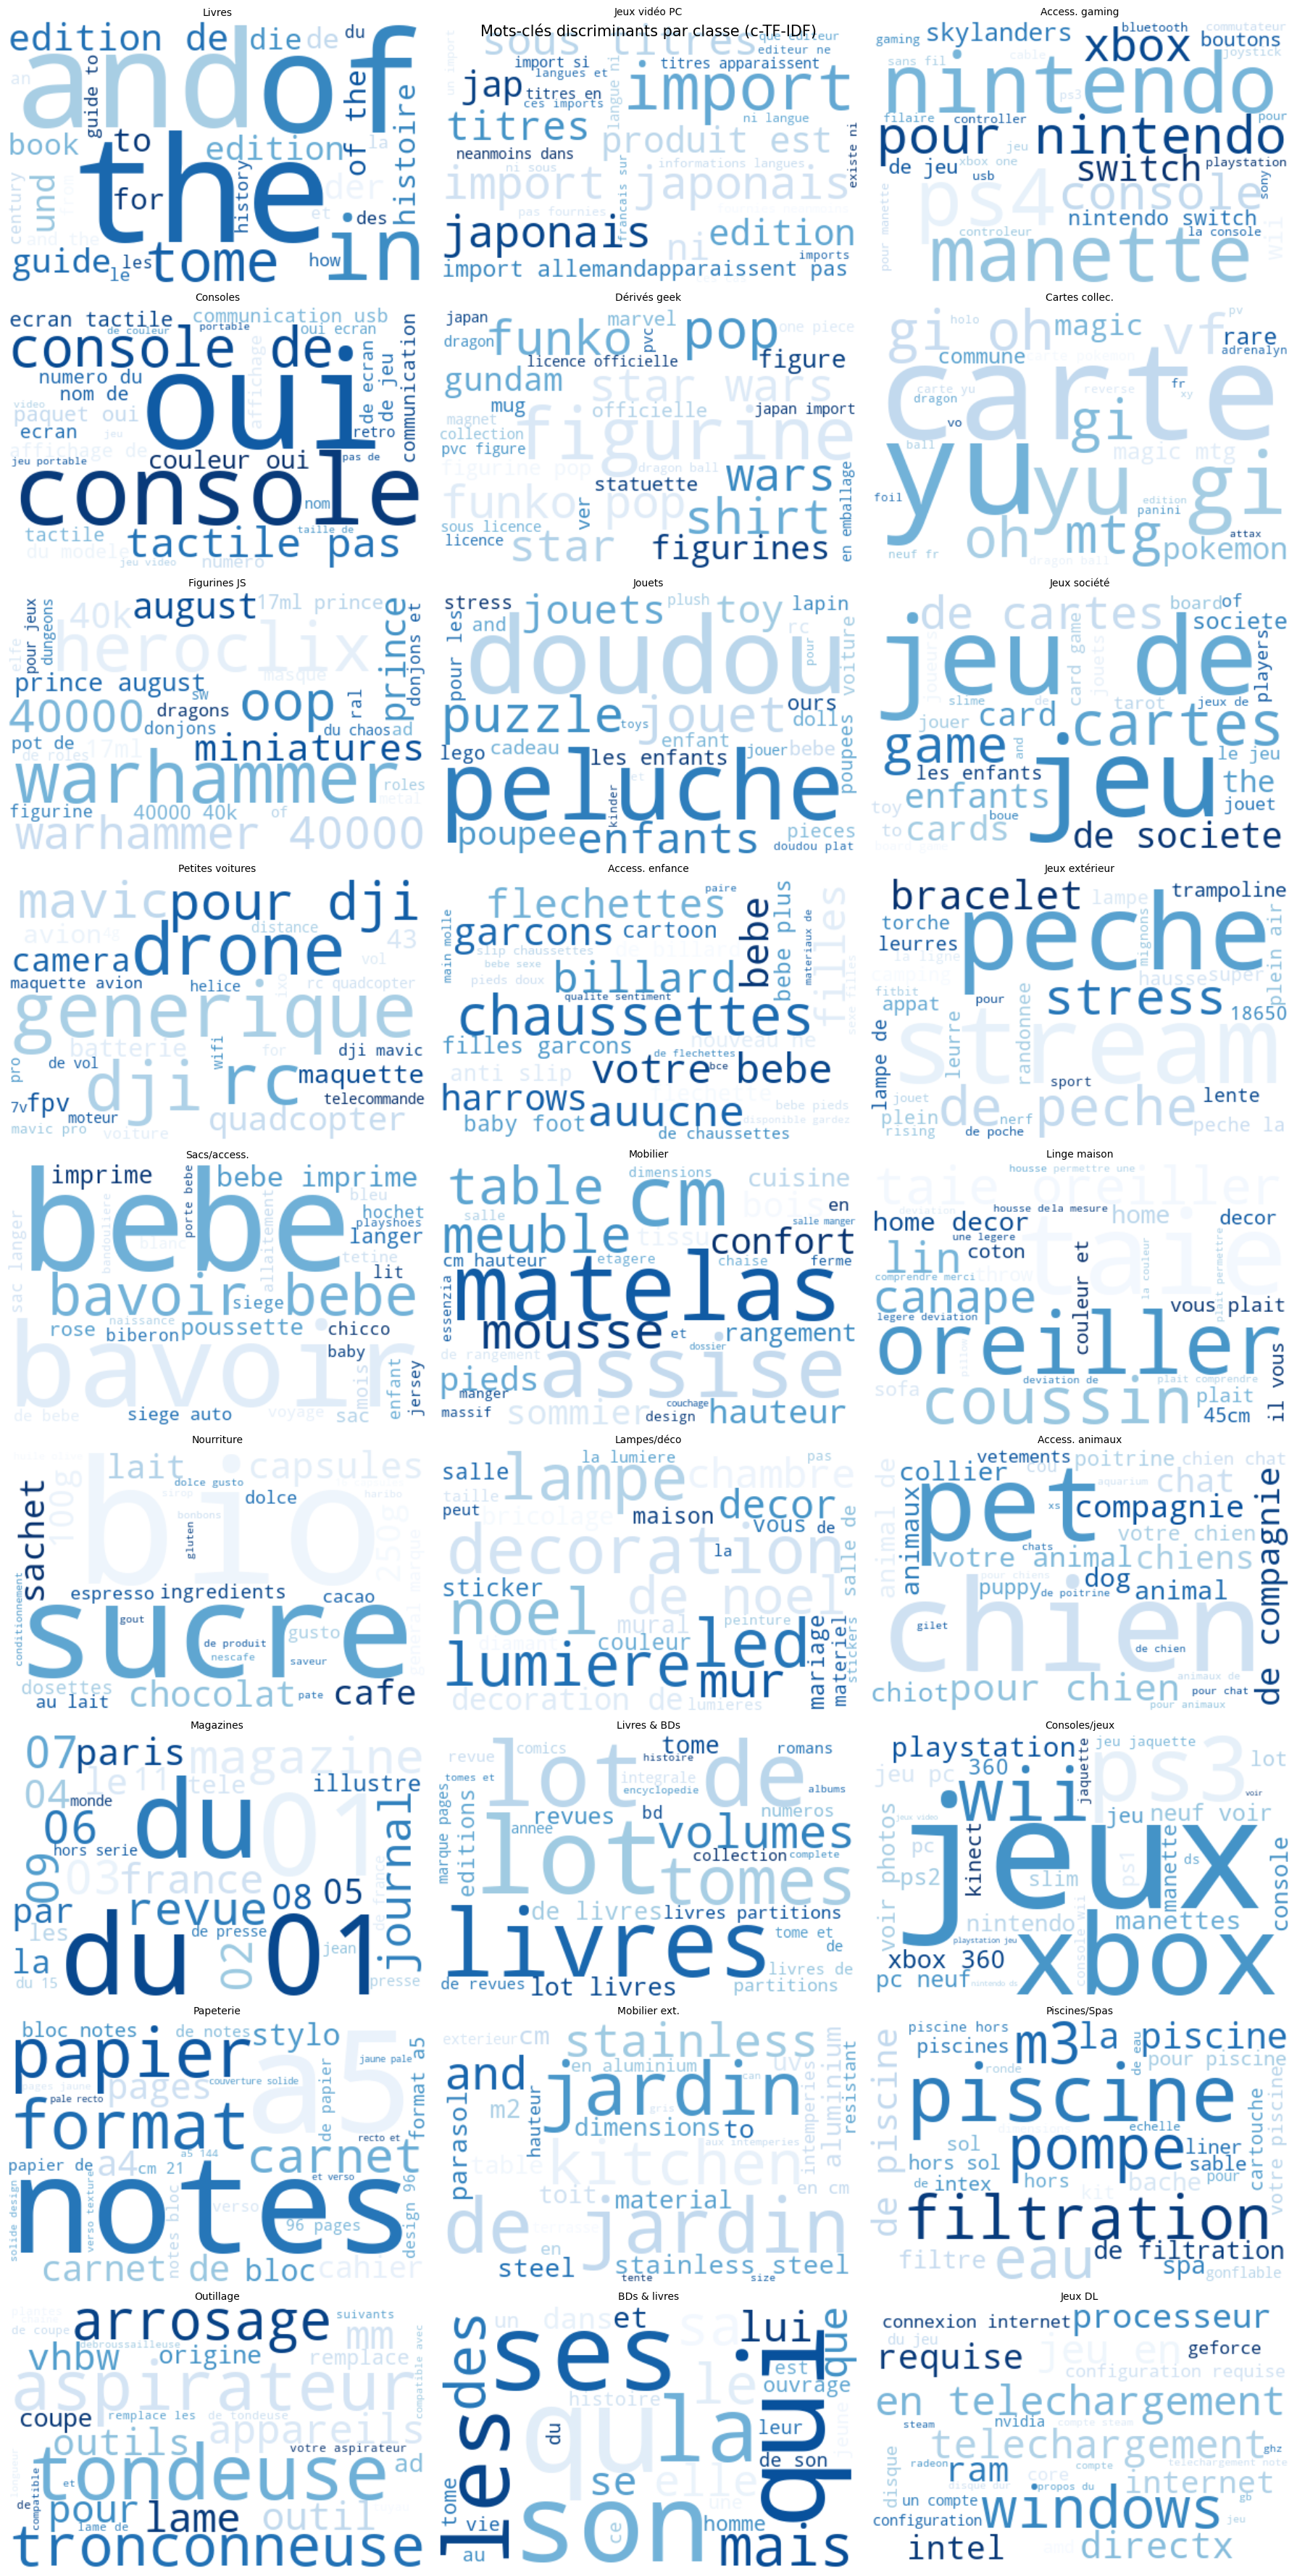

WordClouds sauvegardés.


In [29]:
# ── Visualisation WordCloud des mots-clés par classe ─────────────────────────
# !pip install wordcloud  # décommenter si nécessaire
from wordcloud import WordCloud

n_cols = 3
n_rows = (n_classes + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
fig.suptitle('Mots-clés discriminants par classe (c-TF-IDF)', fontsize=15)

for c in range(n_classes):
    ax = axes[c // n_cols][c % n_cols]
    # Construire le dictionnaire {mot: score} pour le WordCloud
    scores = {vocab[i]: ctfidf_norm[c][i] for i in ctfidf_norm[c].argsort()[::-1][:50]}
    wc = WordCloud(width=400, height=250, background_color='white',
                   max_words=30, colormap='Blues').generate_from_frequencies(scores)
    ax.imshow(wc, interpolation='bilinear')
    ax.set_title(CLASS_NAMES.get(c, str(c)), fontsize=10)
    ax.axis('off')

# Masquer les axes vides
for c in range(n_classes, n_rows * n_cols):
    axes[c // n_cols][c % n_cols].axis('off')

plt.tight_layout()
os.makedirs(os.path.join(BASE_PATH, 'docs', 'figures'), exist_ok=True)
plt.savefig(os.path.join(BASE_PATH, 'docs', 'figures', 'ctfidf_wordclouds.png'), dpi=100, bbox_inches='tight')
plt.show()
print('WordClouds sauvegardés.')

In [30]:
# ── Étape 3 : Features hybrides TF-IDF + similarité cosinus avec centroïdes ──
# Pour chaque document, calculer sa similarité cosinus avec les 27 centroïdes c-TF-IDF
# → 27 features supplémentaires qui encodent "à quelle classe ce texte ressemble le plus"

def compute_cosine_sim_features(X_tfidf, ctfidf_norm):
    """
    Calcule la similarité cosinus entre chaque document et les 27 centroïdes de classe.
    Retourne une matrice (n_docs, 27).
    """
    # Normaliser les vecteurs documents (norme L2)
    X_norm = normalize(X_tfidf, norm='l2')
    # Similarité cosinus = X_norm @ ctfidf_norm.T
    sim = X_norm.dot(ctfidf_norm.T)   # shape: (n_docs, 27)
    return sim

sim_tr  = compute_cosine_sim_features(X_tfidf_tr_kw,  ctfidf_norm)
sim_val = compute_cosine_sim_features(X_tfidf_val_kw, ctfidf_norm)

print(f'Features de similarité cosinus : {sim_tr.shape}  (train)')
print(f'                                 {sim_val.shape}  (val)')
print(f'\nExemple — produit 0 (classe réelle : {y_tr.iloc[0]}) :')
print(f'  Similarités par classe : {sim_tr[0].round(3)}')
print(f'  Classe prédite (argmax) : {sim_tr[0].argmax()}')

# ── Étape 4 : Sélection Chi² sur le TF-IDF (réduction de bruit) ──────────────
# Garder les 20k features les plus discriminantes (Chi²) parmi les 50k
K_CHI2 = 20_000
chi2_selector = SelectKBest(chi2, k=K_CHI2)
X_tfidf_tr_chi2  = chi2_selector.fit_transform(X_tfidf_tr_kw, y_tr)
X_tfidf_val_chi2 = chi2_selector.transform(X_tfidf_val_kw)

print(f'\nAprès sélection Chi² (k={K_CHI2}) :')
print(f'  TF-IDF réduit : {X_tfidf_tr_chi2.shape}')

# ── Étape 5 : Concaténation TF-IDF réduit + 27 features cosinus ──────────────
X_hybrid_tr  = sp.hstack([X_tfidf_tr_chi2,  sp.csr_matrix(sim_tr)],  format='csr')
X_hybrid_val = sp.hstack([X_tfidf_val_chi2, sp.csr_matrix(sim_val)], format='csr')

print(f'  Features hybrides (TF-IDF Chi² + cosinus) : {X_hybrid_tr.shape}')

Features de similarité cosinus : (67932, 27)  (train)
                                 (16984, 27)  (val)

Exemple — produit 0 (classe réelle : 12) :
  Similarités par classe : [0.027 0.018 0.049 0.014 0.033 0.02  0.017 0.074 0.054 0.044 0.052 0.068
 0.121 0.099 0.067 0.028 0.075 0.081 0.032 0.026 0.008 0.048 0.064 0.054
 0.073 0.053 0.016]
  Classe prédite (argmax) : 12

Après sélection Chi² (k=20000) :
  TF-IDF réduit : (67932, 20000)
  Features hybrides (TF-IDF Chi² + cosinus) : (67932, 20027)


In [32]:
# ── LightGBM sur features hybrides ───────────────────────────────────────────
import time

t0 = time.time()

lgb_tr_kw  = lgb.Dataset(X_hybrid_tr,  label=y_tr,  weight=sample_weights_tr)
lgb_val_kw = lgb.Dataset(X_hybrid_val, label=y_val, reference=lgb_tr_kw)

params_kw = {
    'objective':     'multiclass',
    'num_class':     27,
    'learning_rate': 0.05,
    'num_leaves':    127,
    'seed':          42,
    'num_threads':   -1,
    'verbose':       -1
}

model_kw = lgb.train(
    params_kw,
    lgb_tr_kw,
    num_boost_round=1000,
    valid_sets=[lgb_val_kw],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50, verbose=False),
        lgb.log_evaluation(period=100)
    ]
)

y_pred_kw = model_kw.predict(X_hybrid_val).argmax(axis=1)
wf1_kw    = f1_score(y_val, y_pred_kw, average='weighted')
mf1_kw    = f1_score(y_val, y_pred_kw, average='macro')
acc_kw    = (y_val == y_pred_kw).mean()
duration  = time.time() - t0

RESULTS['EXP_T_KW'] = {
    'weighted_f1': wf1_kw,
    'macro_f1':    mf1_kw,
    'accuracy':    acc_kw,
    'best_iter':   model_kw.best_iteration,
    'duration_s':  duration,
    'model':       model_kw,
    'y_pred':      y_pred_kw
}

ref_t03 = RESULTS.get('EXP_T03', {}).get('weighted_f1', None)

print(f'\n{"="*55}')
print(f'  EXP_T_KW — TF-IDF Chi²({K_CHI2}) + c-TF-IDF cosinus')
print(f'{"="*55}')
print(f'  Weighted F1 : {wf1_kw:.4f}')
print(f'  Macro F1    : {mf1_kw:.4f}')
print(f'  Accuracy    : {acc_kw:.4f}')
print(f'  Best iter   : {model_kw.best_iteration}')
print(f'  Durée       : {duration:.0f}s')
if ref_t03 is not None:
    print(f'\n  Référence EXP_T03 (TF-IDF 50k brut) : {ref_t03:.4f}')
    print(f'  Delta vs EXP_T03 : {wf1_kw - ref_t03:+.4f}')
else:
    print(f'\n  Référence EXP_T03 : non disponible dans cette session')
    print(f'  EXP_T03 historique : 0.8274  |  Delta estimé : {wf1_kw - 0.8274:+.4f}')


[100]	valid_0's multi_logloss: 0.603081

  EXP_T_KW — TF-IDF Chi²(20000) + c-TF-IDF cosinus
  Weighted F1 : 0.8321
  Macro F1    : 0.8176
  Accuracy    : 0.8317
  Best iter   : 77
  Durée       : 2322s

  Référence EXP_T03 : non disponible dans cette session
  EXP_T03 historique : 0.8274  |  Delta estimé : +0.0047


---
## EXP_T04 — Désignation seule → traduite en français

**Hypothèse :** La traduction homogénéise le vocabulaire. Apporte-t-elle un gain sur la désignation seule ?

> **Note importante :** La traduction appelle l'API Google Translate (~84k requêtes).  
> Un cache local `.csv` est utilisé pour éviter de retraduite si le notebook est relancé.  
> Temps estimé : 20–40 min (selon la connexion).

In [33]:
!pip install deep-translator langdetect  # décommenter si nécessaire

from deep_translator import GoogleTranslator
from langdetect import detect, LangDetectException
from langdetect import DetectorFactory
DetectorFactory.seed = 42

CACHE_DESIG_PATH = os.path.join(PROCESSED_PATH, 'designation_translated.csv')

def detect_lang_safe(text):
    if not isinstance(text, str) or len(text.strip()) < 5:
        return 'fr'  # texte trop court → on considère FR, pas de traduction
    try:
        return detect(text)
    except LangDetectException:
        return 'fr'

def translate_to_fr(text, lang):
    """Traduit le texte en français uniquement si ce n'est pas déjà du français."""
    if lang == 'fr' or not isinstance(text, str) or text.strip() == '':
        return text
    try:
        return GoogleTranslator(source='auto', target='fr').translate(text[:500])
    except Exception:
        return text  # en cas d'erreur API, garder l'original

# Charger depuis le cache ou traduire
if os.path.exists(CACHE_DESIG_PATH):
    print(f'Cache trouvé : {CACHE_DESIG_PATH} — chargement...')
    cache_df = pd.read_csv(CACHE_DESIG_PATH, index_col=0)
    train['designation_fr'] = cache_df['designation_fr']
    print('Cache chargé.')
else:
    print('Détection des langues...')
    train['lang'] = train['designation_clean'].apply(detect_lang_safe)
    n_non_fr = (train['lang'] != 'fr').sum()
    print(f'Produits non-français à traduire : {n_non_fr} ({n_non_fr/len(train):.1%})')
    
    print('\nTraduction en cours (peut prendre 20-40 min)...')
    train['designation_fr'] = [
        translate_to_fr(text, lang)
        for text, lang in zip(train['designation_clean'], train['lang'])
    ]
    
    train[['designation_fr']].to_csv(CACHE_DESIG_PATH)
    print(f'Cache sauvegardé : {CACHE_DESIG_PATH}')

# Propager sur test
print('\nTraduction du jeu de test...')
test['lang'] = test['designation_clean'].apply(detect_lang_safe)
test['designation_fr'] = [
    translate_to_fr(text, lang)
    for text, lang in zip(test['designation_clean'], test['lang'])
]
print('Terminé.')

ERROR: Invalid requirement: '#'

[notice] A new release of pip is available: 24.0 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Détection des langues...
Produits non-français à traduire : 21594 (25.4%)

Traduction en cours (peut prendre 20-40 min)...
Cache sauvegardé : C:\Users\xavie\Desktop\Rakuten\processed\designation_translated.csv

Traduction du jeu de test...
Terminé.


In [34]:
# Vérification : quelques exemples de traductions
mask_non_fr = train.get('lang', pd.Series(['fr']*len(train))) != 'fr'
if mask_non_fr.any():
    sample_trans = train[mask_non_fr][['designation_clean', 'designation_fr']].sample(5, random_state=42)
    print('Exemples de traductions :')
    for _, row in sample_trans.iterrows():
        print(f'  AVANT : {row["designation_clean"][:80]}')
        print(f'  APRÈS : {row["designation_fr"][:80]}')
        print()

Exemples de traductions :
  AVANT : sim city import usa
  APRÈS : Sim City Importer les États-Unis

  AVANT : lindner t129 finlande année 1856 en 1962
  APRÈS : lindner t129 finlande année 1856 en 1962

  AVANT : ma fabrique de pate à sel abracadabool
  APRÈS : ma fabrique de pate à sel abracadabool

  AVANT : ouarnede mai 1974
  APRÈS : ouarnede depuis 1974

  AVANT : camion man biere kulmbacher ho 1 87 grell
  APRÈS : camion homme bières kulmbacher ho 1 87 criard



In [35]:
# Recalculer les splits sur les données traduites
X_tr_fr  = train.loc[X_tr.index]
X_val_fr = train.loc[X_val.index]

res_t04 = run_experiment(
    exp_id     = 'EXP_T04',
    text_train = X_tr_fr['designation_fr'],
    text_val   = X_val_fr['designation_fr'],
    y_train    = y_tr,
    y_val      = y_val,
    sample_weights = sample_weights_tr,
    label_encoder  = le
)

[100]	valid_0's multi_logloss: 0.765251

  EXP_T04
  Weighted F1 : 0.7787
  Macro F1    : 0.7524
  Accuracy    : 0.7744
  Best iter   : 112
  Durée       : 651s


---
## EXP_T05 — Désignation + Description → traduit en français

**Hypothèse :** La traduction du texte combiné améliore-t-elle EXP_T03 ?  
*(Référence de comparaison : résultat coéquipier avec 20k features = 0.8107)*

In [36]:
CACHE_COMBINED_PATH = os.path.join(PROCESSED_PATH, 'text_combined_translated.csv')

if os.path.exists(CACHE_COMBINED_PATH):
    print(f'Cache trouvé : {CACHE_COMBINED_PATH} — chargement...')
    cache_combined = pd.read_csv(CACHE_COMBINED_PATH, index_col=0)
    train['text_combined_fr'] = cache_combined['text_combined_fr']
    print('Cache chargé.')
else:
    print('Détection des langues sur texte combiné...')
    train['lang_combined'] = train['text_combined'].apply(detect_lang_safe)
    n_non_fr = (train['lang_combined'] != 'fr').sum()
    print(f'Textes combinés non-français : {n_non_fr} ({n_non_fr/len(train):.1%})')
    
    print('Traduction en cours...')
    train['text_combined_fr'] = [
        translate_to_fr(text, lang)
        for text, lang in zip(train['text_combined'], train['lang_combined'])
    ]
    train[['text_combined_fr']].to_csv(CACHE_COMBINED_PATH)
    print(f'Cache sauvegardé.')

X_tr_fr  = train.loc[X_tr.index]
X_val_fr = train.loc[X_val.index]

res_t05 = run_experiment(
    exp_id     = 'EXP_T05',
    text_train = X_tr_fr['text_combined_fr'],
    text_val   = X_val_fr['text_combined_fr'],
    y_train    = y_tr,
    y_val      = y_val,
    sample_weights = sample_weights_tr,
    label_encoder  = le
)

Détection des langues sur texte combiné...
Textes combinés non-français : 15263 (18.0%)
Traduction en cours...
Cache sauvegardé.
[100]	valid_0's multi_logloss: 0.608336

  EXP_T05
  Weighted F1 : 0.8229
  Macro F1    : 0.8057
  Accuracy    : 0.8201
  Best iter   : 107
  Durée       : 4101s


---
## Comparaison des résultats

In [37]:
# Tableau de synthèse
rows = []
labels_map = {
    'EXP_T01':        'Désignation seule',
    'EXP_T02':        'Description seule (+ fallback)',
    'EXP_T03':        'Désig. + Desc. combinées',
    'EXP_T03b':       'Désig. + Desc. + Lemma + Stopwords',
    'EXP_T04':        'Désignation seule → FR',
    'EXP_T05':        'Désig. + Desc. → FR',
    'EXP_T_KW':       'TF-IDF Chi²(20k) + c-TF-IDF cosinus',
    'EXP_T_REF_SEB':  'Référence coéquipier (20k feat.)',
    'EXP_T_REF_TRAD': 'Référence coéquipier traduit (20k feat.)',
}

# Résultats du coéquipier comme référence
RESULTS['EXP_T_REF_SEB'] = {
    'weighted_f1': 0.8184, 'macro_f1': 0.80, 'accuracy': 0.81,
    'best_iter': 109, 'duration_s': None
}
RESULTS['EXP_T_REF_TRAD'] = {
    'weighted_f1': 0.8107, 'macro_f1': 0.79, 'accuracy': 0.81,
    'best_iter': 106, 'duration_s': None
}

for exp_id, res in RESULTS.items():
    rows.append({
        'Exp_ID':      exp_id,
        'Description': labels_map.get(exp_id, exp_id),
        'Weighted F1': round(res['weighted_f1'], 4),
        'Macro F1':    round(res['macro_f1'], 4),
        'Accuracy':    round(res['accuracy'], 4),
        'Best Iter':   res['best_iter'],
    })

df_results = pd.DataFrame(rows).sort_values('Weighted F1', ascending=False).reset_index(drop=True)

display(df_results.style
    .background_gradient(subset=['Weighted F1', 'Macro F1'], cmap='RdYlGn')
    .format({'Weighted F1': '{:.4f}', 'Macro F1': '{:.4f}', 'Accuracy': '{:.4f}'})
)

,Exp_ID,Description,Weighted F1,Macro F1,Accuracy,Best Iter
0,EXP_T_KW,TF-IDF Chi²(20k) + c-TF-IDF cosinus,0.8321,0.8176,0.8317,77
1,EXP_T05,Désig. + Desc. → FR,0.8229,0.8057,0.8201,107
2,EXP_T_REF_SEB,Référence coéquipier (20k feat.),0.8184,0.8000,0.8100,109
3,EXP_T_REF_TRAD,Référence coéquipier traduit (20k feat.),0.8107,0.7900,0.8100,106
4,EXP_T04,Désignation seule → FR,0.7787,0.7524,0.7744,112


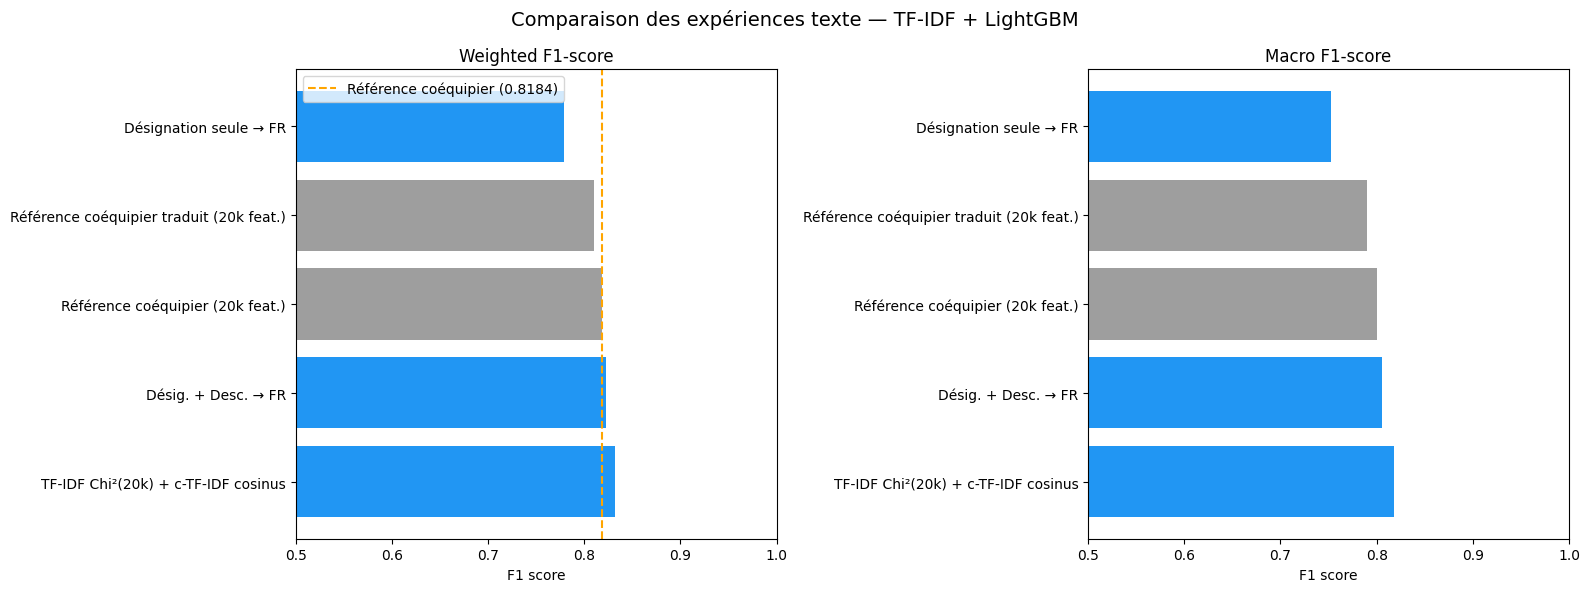

In [38]:
# Graphique comparatif
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Comparaison des expériences texte — TF-IDF + LightGBM', fontsize=14)

colors = ['#2196F3' if 'REF' not in e else '#9E9E9E' for e in df_results['Exp_ID']]

axes[0].barh(df_results['Description'], df_results['Weighted F1'], color=colors)
axes[0].axvline(0.8184, color='orange', linestyle='--', label='Référence coéquipier (0.8184)')
axes[0].set_title('Weighted F1-score')
axes[0].set_xlabel('F1 score')
axes[0].legend()
axes[0].set_xlim(0.5, 1.0)

axes[1].barh(df_results['Description'], df_results['Macro F1'], color=colors)
axes[1].set_title('Macro F1-score')
axes[1].set_xlabel('F1 score')
axes[1].set_xlim(0.5, 1.0)

plt.tight_layout()
plt.savefig(os.path.join(BASE_PATH, 'docs', 'figures', 'mod_text_experiments.png'), dpi=150, bbox_inches='tight')
plt.show()

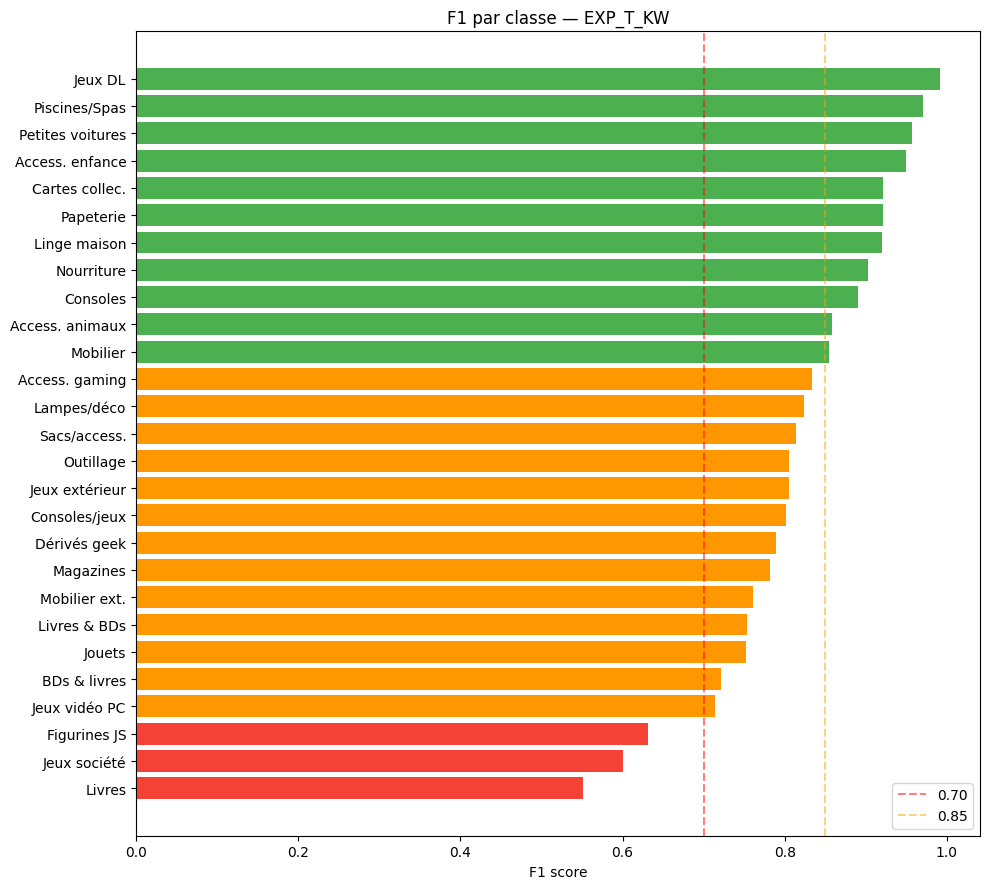


Classes difficiles (F1 < 0.70) — EXP_T_KW :


,Classe,F1
0,Livres,0.551724
8,Jeux société,0.600496
6,Figurines JS,0.630872


In [39]:
# F1 par classe pour la meilleure expérience
best_exp = df_results.iloc[0]['Exp_ID']
if best_exp in RESULTS and 'y_pred' in RESULTS[best_exp]:
    y_pred_best = RESULTS[best_exp]['y_pred']
    f1_per_class = f1_score(y_val, y_pred_best, average=None)
    class_labels = le.inverse_transform(range(27))
    
    CLASS_NAMES = {
        10: 'Livres', 40: 'Jeux vidéo PC', 50: 'Access. gaming',
        60: 'Consoles', 1140: 'Dérivés geek', 1160: 'Cartes collec.',
        1180: 'Figurines JS', 1280: 'Jouets', 1281: 'Jeux société',
        1300: 'Petites voitures', 1301: 'Access. enfance', 1302: 'Jeux extérieur',
        1320: 'Sacs/access.', 1560: 'Mobilier', 1920: 'Linge maison',
        1940: 'Nourriture', 2060: 'Lampes/déco', 2220: 'Access. animaux',
        2280: 'Magazines', 2403: 'Livres & BDs', 2462: 'Consoles/jeux',
        2522: 'Papeterie', 2582: 'Mobilier ext.', 2583: 'Piscines/Spas',
        2585: 'Outillage', 2705: 'BDs & livres', 2905: 'Jeux DL'
    }
    
    labels_names = [CLASS_NAMES.get(c, str(c)) for c in class_labels]
    
    df_f1_class = pd.DataFrame({
        'Classe': labels_names,
        'F1': f1_per_class
    }).sort_values('F1')
    
    fig, ax = plt.subplots(figsize=(10, 9))
    colors_bar = ['#F44336' if f < 0.7 else '#FF9800' if f < 0.85 else '#4CAF50' for f in df_f1_class['F1']]
    ax.barh(df_f1_class['Classe'], df_f1_class['F1'], color=colors_bar)
    ax.axvline(0.7,  color='red',    linestyle='--', alpha=0.5, label='0.70')
    ax.axvline(0.85, color='orange', linestyle='--', alpha=0.5, label='0.85')
    ax.set_title(f'F1 par classe — {best_exp}')
    ax.set_xlabel('F1 score')
    ax.legend()
    plt.tight_layout()
    plt.show()
    
    # Classes difficiles (F1 < 0.70)
    hard_classes = df_f1_class[df_f1_class['F1'] < 0.70]
    print(f'\nClasses difficiles (F1 < 0.70) — {best_exp} :')
    display(hard_classes.sort_values('F1'))

In [40]:
# Sauvegarde du tableau de résultats
os.makedirs(os.path.join(BASE_PATH, 'docs', 'figures'), exist_ok=True)
df_results.drop(columns=['Best Iter'], errors='ignore').to_csv(
    os.path.join(PROCESSED_PATH, 'text_experiments_results.csv'), index=False
)
print('Résultats sauvegardés : processed/text_experiments_results.csv')

Résultats sauvegardés : processed/text_experiments_results.csv


---
## Conclusions

*(À compléter après exécution)*

| Question | Résultat observé |
|----------|------------------|
| Désignation seule vs. combiné | ? |
| Description seule apporte-t-elle quelque chose ? | ? |
| La traduction aide-t-elle ? | Référence coéquipier : Non (−0.0077) |
| Meilleure configuration textuelle | ? |

**Prochain notebook :** `modelisation_images.ipynb` — expériences sur le preprocessing image (auto-crop, netteté, images utilisables).